# Figures (ICC 2026)

In [ ]:
import os
try:
    from google.colab import files
    if not all(os.path.exists(f) for f in ('results_05_mlp.csv', 'results_05_cnn.csv',
                                           'results_07.csv')):
        files.upload()
except ImportError:
    pass

In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

DECIMAL = '.'
COR = {'mlp': '#2a78d6', 'cnn': '#eb6834'}
MARC = {'mlp': 'o', 'cnn': 's'}
LINHA = {'mlp': '-', 'cnn': '--'}
NOME = {'mlp': 'MLP', 'cnn': '1D-CNN'}
TINTA, TINTA2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
CINZA_ESC, CINZA_CLARO = '#52514e', '#c9c8c4'
DESL = {'mlp': 0.95, 'cnn': 1.05}

mpl.rcParams.update({
    'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix',
    'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA, 'xtick.color': TINTA2,
    'ytick.color': TINTA2, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6,
    'ytick.major.width': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.5,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42,
})
COL = 3.5


def num(v, nd):
    return f"{v:.{nd}f}".replace('.', DECIMAL)


def virgula(nd):
    return FuncFormatter(lambda v, _: num(v, nd))


def eps_fmt(v, _):
    return f"{v:g}".replace('.', DECIMAL)

In [ ]:
mlp = pd.read_csv('results_05_mlp.csv')
cnn = pd.read_csv('results_05_novo_cnn.csv')
nidd = pd.read_csv('results_07.csv')
DADOS = {'CVE5G': {'mlp': mlp, 'cnn': cnn},
         '5G-NIDD': {'mlp': nidd[nidd['model'] == 'mlp'], 'cnn': nidd[nidd['model'] == 'cnn']}}
UNIF = ['FL+DP s=2', 'FL+DP s=1', 'FL+DP s=0.5']
ALVO = ['FL+DP eps<=1', 'FL+DP eps<=2']


def resumo(df, cfg, col, esc=1.0):
    g = df[df['config'] == cfg]
    if g.empty:
        return None
    v = esc * g[col].astype(float)
    return dict(eps=g['eps'].astype(float).mean(), m=v.mean(), s=v.std(ddof=1),
                lo=v.min(), hi=v.max(), n=len(v))

## Figure 1: F1 macro and FAR

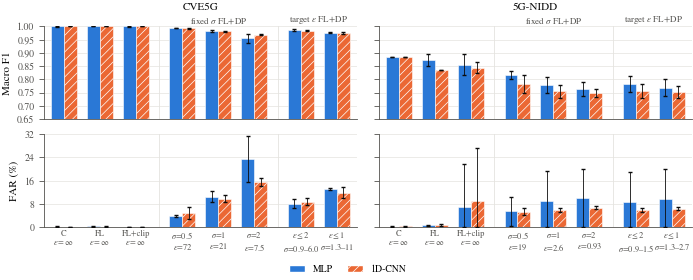

In [ ]:
BARRAS_CFG = [('Central', 'C'),
              ('FL', 'FL'),
              ('FL+clip (s=0)', 'FL+clip'),
              ('FL+DP s=0.5', r'$\sigma$=' + num(0.5, 1)),
              ('FL+DP s=1', r'$\sigma$=1'),
              ('FL+DP s=2', r'$\sigma$=2'),
              ('FL+DP eps<=2', r'$\varepsilon\leq$2'),
              ('FL+DP eps<=1', r'$\varepsilon\leq$1')]
GRUPOS = [('', [0, 1, 2]), (r'fixed $\sigma$ FL+DP', [3, 4, 5]),
          (r'target $\varepsilon$ FL+DP', [6, 7])]
SEM_DP = ('Central', 'FL', 'FL+clip (s=0)')   # ε = ∞
LARG = 0.36
ESPACO = 0.3
YLIM = {'macro_f1': (0.65, 1.0), 'far': (0, 32)}
YPASSO = {'macro_f1': 0.05, 'far': 8}
LARGURA_2COL = 7.16


def g2(v):
    '''2 algarismos significativos, com o separador decimal do artigo.'''
    return eps_fmt(float(f'{v:.2g}'), None)


def rotulo(ds, cfg, nome):
    df = DADOS[ds]['mlp']
    if cfg in SEM_DP:
        return nome + '\n' + r'$\varepsilon=\infty$'
    if 'eps<=' in cfg:
        sig = np.concatenate([np.array(s.split(';'), dtype=float)
                              for s in df.loc[df['config'] == cfg, 'sigma_clients']])
        g1 = lambda v: num(v, 1) if v < 10 else num(v, 0)   # 1 casa: cabe no rótulo
        return nome + '\n' + rf'$\sigma$={g1(sig.min())}–{g1(sig.max())}'
    return nome + '\n' + r'$\varepsilon$=' + g2(resumo(df, cfg, 'eps')['eps'])


def fig_tradeoff_barras():
    mpl.rcParams.update({'hatch.color': 'white', 'hatch.linewidth': 0.5})
    fig, axs = plt.subplots(2, 2, figsize=(LARGURA_2COL, 2.9), sharex='col', sharey='row')
    metricas = [('macro_f1', 'Macro F1', 1.0, 2), ('far', 'FAR (%)', 100.0, 0)]
    grupo_de = {n: g for g, (_, idx) in enumerate(GRUPOS) for n in idx}
    x = np.array([n + ESPACO * grupo_de[n] for n in range(len(BARRAS_CFG))])
    for j, ds in enumerate(DADOS):
        for i, (col, rot, esc, nd) in enumerate(metricas):
            ax = axs[i, j]
            for k, (mod, df) in enumerate(DADOS[ds].items()):
                dx = (k - 0.5) * LARG
                for xx, (cfg, _) in zip(x, BARRAS_CFG):
                    r = resumo(df, cfg, col, esc)
                    if r is None:
                        continue
                    s = 0.0 if np.isnan(r['s']) else r['s']
                    baixo = min(s, r['m']) if col == 'far' else s
                    ax.bar(xx + dx, r['m'], LARG, color=COR[mod], edgecolor='white', lw=0.4,
                           hatch='////' if mod == 'cnn' else None, zorder=3)
                    ax.errorbar(xx + dx, r['m'], yerr=[[baixo], [s]], fmt='none',
                                ecolor=TINTA, elinewidth=0.6, capsize=1.5, zorder=4)
            for g in range(1, len(GRUPOS)):
                ini = GRUPOS[g][1][0]
                ax.axvline((x[ini - 1] + x[ini]) / 2, color=GRADE, lw=0.6, zorder=1)
            if i == 0:
                for nome_g, idx in GRUPOS:
                    ax.text(x[idx].mean(), 1.0, nome_g, transform=ax.get_xaxis_transform(),
                            ha='center', va='bottom', fontsize=6.5, color=TINTA2)
                ax.set_title(ds, color=TINTA, pad=12)
            ax.set_xlim(x[0] - 0.55, x[-1] + 0.55)
            ax.grid(axis='x', visible=False)
            ax.tick_params(axis='x', length=0)
            ax.yaxis.set_major_formatter(virgula(nd))
            ax.set_ylim(*YLIM[col])
            ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(YPASSO[col]))
            if j == 0:
                ax.set_ylabel(rot)
            if i == 1:
                ax.set_xticks(x, [rotulo(ds, c, n) for c, n in BARRAS_CFG])
                ax.tick_params(axis='x', labelsize=6, pad=2)
    leg = [Patch(facecolor=COR[m], edgecolor='white', hatch='////' if m == 'cnn' else None,
                 label=NOME[m]) for m in COR]
    fig.legend(handles=leg, loc='lower center', ncol=2, frameon=False,
               bbox_to_anchor=(0.5, -0.01), handlelength=1.6, columnspacing=1.5)
    fig.tight_layout(rect=(0, 0.05, 1, 1), h_pad=0.5, w_pad=1.5)
    return fig


f = fig_tradeoff_barras()
f.savefig('fig_tradeoff_barras_en.pdf'); f.savefig('fig_tradeoff_barras_en.png')
plt.show()


## Figure 2 - Effect of the decision threshold calibrated on the validation set

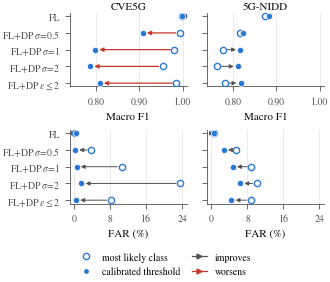

In [ ]:
CAL = [('FL', 'FL'), ('FL+DP s=0.5', r'FL+DP $\sigma$=' + num(0.5, 1)),
       ('FL+DP s=1', r'FL+DP $\sigma$=1'), ('FL+DP s=2', r'FL+DP $\sigma$=2'),
       ('FL+DP eps<=2', r'FL+DP $\varepsilon\leq$2')]
MET_CAL = [('macro_f1', 'Macro F1', 1.0, +1, 2), ('far', 'FAR (%)', 100.0, -1, 0)]
TOL = {'far': 0.5, 'macro_f1': 0.005}
COR_PIORA = '#c8372d'
XLIM_CAL = {'far': (-1, 25), 'macro_f1': (0.74, 1.01)}
XPASSO_CAL = {'far': 8, 'macro_f1': 0.1}
ROT_CAL = ('most likely class', 'calibrated threshold', 'improves', 'worsens')


def fig_calib():
    fig, axs = plt.subplots(2, 2, figsize=(COL, 2.9), sharex='row', sharey=True)
    y = np.arange(len(CAL))
    for j, ds in enumerate(DADOS):
        df = DADOS[ds]['mlp']
        for i, (col, rot, esc, sentido, nd) in enumerate(MET_CAL):
            ax = axs[i, j]
            xs = []
            for yy, (k, _) in zip(y, CAL):
                g = df[df['config'] == k]
                if g.empty:
                    continue
                x0, x1 = esc * g[col].mean(), esc * g[col + '_cal'].mean()
                xs += [x0, x1]
                piora = sentido * (x1 - x0) < -TOL[col] * esc
                cor = COR_PIORA if piora else TINTA2
                ax.annotate('', xy=(x1, yy), xytext=(x0, yy),
                            arrowprops=dict(arrowstyle='-|>', color=cor, lw=0.9 if piora else 0.7,
                                            shrinkA=3, shrinkB=3, mutation_scale=6), zorder=2)
                ax.plot(x0, yy, 'o', ms=4.5, mfc='white', mec=COR['mlp'], mew=1.0, zorder=3)
                ax.plot(x1, yy, 'o', ms=4.5, mfc=COR['mlp'], mec='white', mew=0.5, zorder=4)
            ax.set_xlim(*XLIM_CAL[col])
            ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(XPASSO_CAL[col]))
            if not (XLIM_CAL[col][0] <= min(xs) and max(xs) <= XLIM_CAL[col][1]):
                print(f'aviso: {ds} {col} tem pontos fora de XLIM_CAL', min(xs), max(xs))
            ax.xaxis.set_major_formatter(virgula(nd))
            ax.grid(axis='y', visible=False)
            ax.set_xlabel(rot)
            if i == 0:
                ax.set_title(ds, color=TINTA, pad=3)
    axs[0, 0].set_yticks(y, [r for _, r in CAL])
    axs[0, 0].invert_yaxis()
    seta = dict(ls='-', lw=0.9, marker='>', ms=3.5, markevery=[-1])
    leg = [Line2D([], [], ls='none', marker='o', ms=4.5, mfc='white', mec=COR['mlp'],
                  label=ROT_CAL[0]),
           Line2D([], [], ls='none', marker='o', ms=4.5, mfc=COR['mlp'], mec='white',
                  label=ROT_CAL[1]),
           Line2D([0, 1], [0, 0], color=TINTA2, mfc=TINTA2, mec=TINTA2, label=ROT_CAL[2], **seta),
           Line2D([0, 1], [0, 0], color=COR_PIORA, mfc=COR_PIORA, mec=COR_PIORA,
                  label=ROT_CAL[3], **seta)]
    fig.legend(handles=leg, loc='lower center', ncol=2, frameon=False,
               bbox_to_anchor=(0.5, -0.02), handlelength=1.6, columnspacing=1.2)
    fig.tight_layout(rect=(0, 0.1, 1, 1), h_pad=0.8, w_pad=1.0)
    return fig


f = fig_calib()
f.savefig('fig_calib_en.pdf'); f.savefig('fig_calib_en.png')
plt.show()


## Figure 3: Total training time

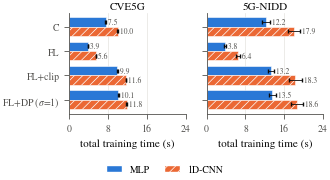

In [ ]:
CUSTO = [('Central', 'C'), ('FL', 'FL'), ('FL+clip (s=0)', 'FL+clip'),
         ('FL+DP s=1', r'FL+DP ($\sigma$=1)')]
TEMPO = 'client_parallel_s'
ROT_CUSTO = 'total training time (s)'
XMAX_CUSTO, XPASSO_CUSTO = 24, 8
ALT = 0.38


def fig_custo():
    mpl.rcParams.update({'hatch.color': 'white', 'hatch.linewidth': 0.5})
    fig, axs = plt.subplots(1, 2, figsize=(COL, 1.9), sharex=True, sharey=True)
    y = np.arange(len(CUSTO))
    for ax, ds in zip(axs, DADOS):
        topo = 0
        for k, (mod, df) in enumerate(DADOS[ds].items()):
            dy = (k - 0.5) * ALT                       # MLP em cima, 1D-CNN embaixo
            m = np.array([df[df['config'] == c][TEMPO].mean() for c, _ in CUSTO])
            s = np.array([df[df['config'] == c][TEMPO].std(ddof=1) for c, _ in CUSTO])
            s = np.nan_to_num(s)
            ax.barh(y + dy, m, height=ALT, color=COR[mod], edgecolor='white', lw=0.4,
                    hatch='////' if mod == 'cnn' else None, zorder=2,
                    xerr=s, error_kw=dict(ecolor=TINTA, elinewidth=0.6, capsize=1.2))
            topo = max(topo, np.nanmax(m + s))
            for yy, mm, ss in zip(y + dy, m, s):
                if not np.isnan(mm):
                    ax.text(mm + ss, yy, ' ' + num(mm, 1), va='center', fontsize=5.5,
                            color=TINTA2)
        ax.set_xlim(0, XMAX_CUSTO)
        if topo > XMAX_CUSTO:
            print(f'aviso: {ds} passa de XMAX_CUSTO ({topo:.1f} s)')
        ax.set_title(ds, color=TINTA, pad=3)
        ax.set_xlabel(ROT_CUSTO)
        ax.xaxis.set_major_formatter(virgula(0))
        ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(XPASSO_CUSTO))
        ax.grid(axis='y', visible=False)
    axs[0].set_yticks(y, [r for _, r in CUSTO])
    axs[0].invert_yaxis()
    leg = [Patch(facecolor=COR[m], edgecolor='white', hatch='////' if m == 'cnn' else None,
                 label=NOME[m]) for m in COR]
    fig.legend(handles=leg, loc='lower center', ncol=2, frameon=False,
               bbox_to_anchor=(0.5, -0.02), handlelength=1.6, columnspacing=1.5)
    fig.tight_layout(rect=(0, 0.1, 1, 1), w_pad=1.0)
    return fig


f = fig_custo()
f.savefig('fig_custo_en.pdf'); f.savefig('fig_custo_en.png')
plt.show()


In [ ]:
try:                                   # baixa as figuras no Colab
    for n in ('fig_tradeoff_barras_en', 'fig_calib_en', 'fig_custo_en'):
        files.download(f'{n}.pdf')
except NameError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>